In [1]:
import numpy as np
import os
import seaborn as sns
import pandas as pd
from sklearn.mixture import GaussianMixture
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors

from general_solver import omt, sample_mm, mmd_rbf
from exp_functions import points_transport
from utils import RingSampler

%load_ext autoreload
%autoreload 2

In [2]:
saving_path = './figures/'
os.makedirs(saving_path, exist_ok=True)
# set the optimization parameters
eps = 0.01
max_iter = int(1e5)
stop_thr = 1e-6
fontsize = 22

# set the vidualization parameters
color_source = '#ff715b'
color_target = '#29335C' 
color_omt = '#eeab00'


/tmp/ipykernel_3057374/3981823371.py:16: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(samples_gauss_2d[:, 0], samples_gauss_2d[:, 1], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.9)


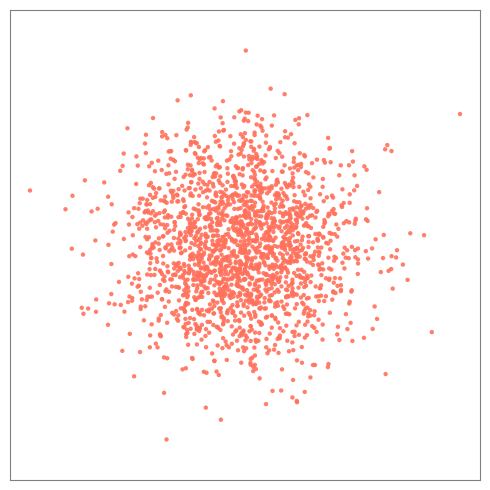

In [3]:
# Generate 2D Gaussian samples
n_samples = int(2000)
mean_0 = np.array([[0.0, 0.0]]) # Mean vector [mean_x, mean_y]
# Covariance matrix: [[var_x, cov_xy], [cov_xy, var_y]]
# Must be symmetric and positive semi-definite
sigma_0 = np.array([[[1.0, 0.], [0.0, 1.0]]])
random_seed = 0

# Generate samples
# Returns shape (n_samples_2d, 2)
np.random.seed(random_seed)  # Set the random seed
samples_gauss_2d = np.random.multivariate_normal(mean=mean_0[0], cov=sigma_0[0], size=n_samples)

# plot the results
plt.figure(figsize=(5, 5))
plt.scatter(samples_gauss_2d[:, 0], samples_gauss_2d[:, 1], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.9)
plt.axis('equal')
plt.grid(False)
plt.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax = plt.gca()  # Get the current axes
ax.spines['top'].set_color('gray')
ax.spines['right'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['bottom'].set_color('gray')
plt.tight_layout()
plt.savefig(saving_path + 'guass_2d.pdf', dpi=300)

/tmp/ipykernel_3057374/2777588638.py:25: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=15, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7)


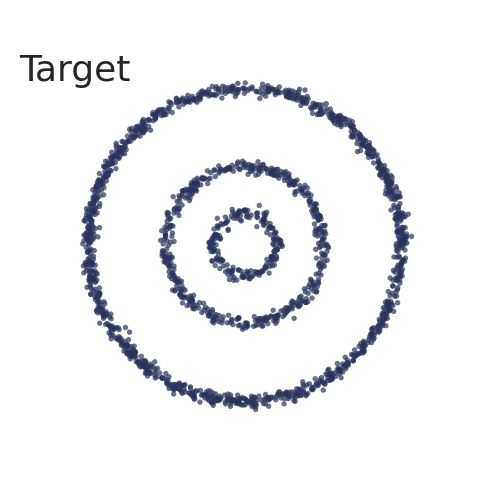

In [4]:
n_rings = 3
radii = [1.0, 2.5, 5.0] # Radii of the concentric rings
n_samples_per_ring = [200, 500, 1300] # Number of samples for each ring
noise_level = 0.1 # Noise level for all rings

# --- Generate data for all rings ---
all_x = []
all_y = []

for i in range(n_rings):
    x_ring, y_ring = RingSampler(radii[i], noise_level, n_samples_per_ring[i])
    all_x.append(x_ring)
    all_y.append(y_ring)

# Concatenate points from all rings
x_total = np.concatenate(all_x)
y_total = np.concatenate(all_y)

samples_rings_2d =np.vstack((x_total, y_total)).T

# Plot the results
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.set_style("whitegrid") # Set style to whitegrid for better visibility
# Plot original Swiss Roll data
ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=15, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7)
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
# ax.axis('equal')
ax.text(0.02, 0.85, 'Target', fontsize=fontsize+4, transform=ax.transAxes)
ax.grid(False)
# ax.spines['top'].set_color('gray')
# ax.spines['right'].set_color('gray')
# ax.spines['left'].set_color('gray')
# ax.spines['bottom'].set_color('gray')
ax.axis('off')
plt.tight_layout()
ax.set_ylim([-7.5,7.5])
ax.set_xlim([-7.5,7.5])

plt.savefig(saving_path + 'figure_2_concentric_rings_target.pdf', dpi=300)
plt.show()

In [9]:
K0 = 1
K1 = 100
omt_w, solver_dict = omt(
                        data_source=samples_gauss_2d,
                        data_target=samples_rings_2d,
                        n_components=(K0, K1),
                        eps_gmm=eps,
                        eps_w=eps,
                        method='cvx',
                        fitting_mode_source='gauss',
                        fitting_mode_target='exp',
                        cov_type='diag',
                        max_iter=max_iter,
                        n_iter_em=1000,
                        stop_thr=stop_thr,
                        verbose=True,
                    )

Fitted a GMM with 1 components.
Model converged: True
Number of iterations: 2
--------------------------------------------------
Fitting Exp-only K=100, N=2000, D=2


/fsx/ubuntu/allen-dev/ymarghi/test/exp_functions.py:218: RuntimeWarning: overflow encountered in exp
  np.exp(-c_rate * diff),
/fsx/ubuntu/allen-dev/ymarghi/test/exp_functions.py:219: RuntimeWarning: overflow encountered in exp
  np.exp( d_rate * diff))


  EM done: 100A  BIC=17205.2

─── Result: 0 Gaussian + 100 Exp  BIC=17205.2 ───
  Exp 1: w=0.006  b=[-1.32   2.115]  c=[11.329 54.365]  d=[ 7.41  43.312]
  Exp 2: w=0.005  b=[ 0.069 -2.568]  c=[79.907 22.711]  d=[ 7.061 22.381]
  Exp 3: w=0.009  b=[4.89  0.974]  c=[10.282 29.612]  d=[17.361  9.643]
  Exp 4: w=0.011  b=[-4.517 -2.205]  c=[15.082  6.616]  d=[12.751 16.656]
  Exp 5: w=0.013  b=[ 3.817 -3.545]  c=[113.19   4.87]  d=[  6.662 109.501]
  Exp 6: w=0.013  b=[2.421 4.164]  c=[7.413 5.679]  d=[  5.759 490.023]
  Exp 7: w=0.017  b=[-4.95   0.388]  c=[14.942 56.022]  d=[11.989  2.882]
  Exp 8: w=0.002  b=[-0.411 -4.938]  c=[ 486.48  3431.822]  d=[11.873 10.927]
  Exp 9: w=0.010  b=[ 2.353 -1.327]  c=[1.494534e+04 6.453000e+00]  d=[5.039 7.348]
  Exp 10: w=0.017  b=[-3.252  3.702]  c=[11.177  8.062]  d=[ 8.072 13.878]
  Exp 11: w=0.011  b=[-2.423 -1.134]  c=[10.645  1.754]  d=[1803.253  286.884]
  Exp 12: w=0.015  b=[2.229 1.14 ]  c=[11.23  10.635]  d=[26.477  2.704]
  Exp 13: w=0.0

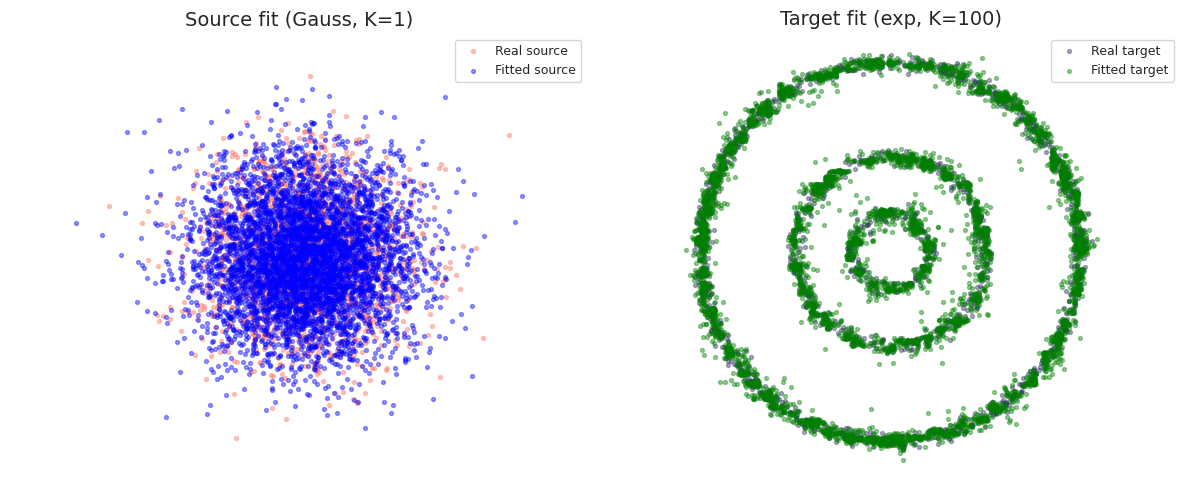

In [10]:
mm_s_gauss = solver_dict['mm_s']
mm_t_gauss = solver_dict['mm_t']

n_samples = 5000
smp_s_gauss, _ = sample_mm(mm_s_gauss, n_samples=n_samples, random_state=42)
smp_t_gauss, _ = sample_mm(mm_t_gauss, n_samples=n_samples, random_state=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(samples_gauss_2d[:, 0], samples_gauss_2d[:, 1], s=8, c=color_source, alpha=0.4, label='Real source')
ax.scatter(smp_s_gauss[:, 0], smp_s_gauss[:, 1], s=8, c='blue', alpha=0.4, label='Fitted source')
ax.set_title(f'Source fit (Gauss, K={K0})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

ax = axes[1]
ax.scatter(samples_rings_2d[:, 0], samples_rings_2d[:, 1], s=8, c=color_target, alpha=0.4, label='Real target')
ax.scatter(smp_t_gauss[:, 0], smp_t_gauss[:, 1], s=8, c='green', alpha=0.4, label='Fitted target')
ax.set_title(f'Target fit (exp, K={K1})', fontsize=14)
ax.legend(fontsize=9); ax.axis('equal'); ax.axis('off')

plt.tight_layout()
plt.savefig(saving_path + 'fit_quality_gauss.pdf', dpi=300)
plt.show()

In [11]:
tnsp_smp = points_transport(samples_gauss_2d, omt_w, solver_dict)

/tmp/ipykernel_3057374/4057899175.py:26: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
/tmp/ipykernel_3057374/4057899175.py:27: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(samples_rings_2d[:num_display, 0], samples_rings_2d[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
/tmp/ipykernel_3057374/4057899175.py:28: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=c

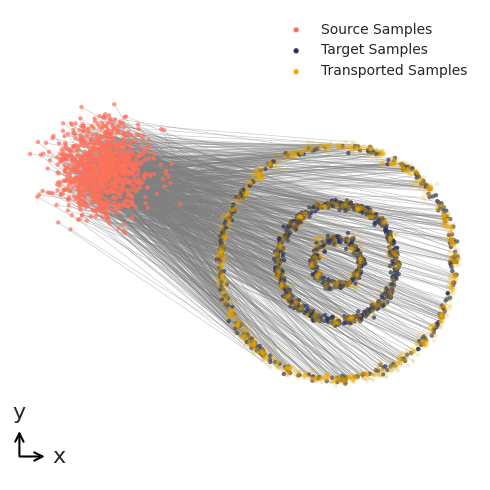

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.set_style("whitegrid") 
scale = 1
shift = [-10, 4]

num_total = len(samples_gauss_2d)
num_display = 1000  # Number of samples to visualize
indices = np.random.choice(num_total, size=min(num_total, num_display), replace=False)

# 1. Pre-calculate source coordinates for clarity
src_x = scale * samples_gauss_2d[:, 0] + shift[0]
src_y = scale * samples_gauss_2d[:, 1] + shift[1]
tr_x = tnsp_smp[:, 0]
tr_y = tnsp_smp[:, 1]

# 2. Draw lines between each pair of source and transported samples
# We loop through the points and plot a gray line for each correspondence
for i in range(num_display):
    ax.plot([src_x[indices[i]], tr_x[indices[i]]], [src_y[indices[i]], tr_y[indices[i]]], 
            color='gray', 
            linestyle='-', 
            linewidth=0.5, 
            alpha=0.4, 
            zorder=1) # Lower zorder to stay behind the dots

ax.scatter(src_x[indices], src_y[indices], s=10, c=color_source, facecolors=color_source, edgecolors='none', alpha=0.7, zorder=1, label='Source Samples')
ax.scatter(samples_rings_2d[:num_display, 0], samples_rings_2d[:num_display, 1], s=10, c=color_target, facecolors=color_target, edgecolors='none', alpha=0.7, zorder=1, label='Target Samples')
ax.scatter(tr_x, tr_y, s=10, c=color_omt, facecolors=color_omt, edgecolors='none', alpha=0.2, zorder=2, label='Transported Samples')

# Formatting
ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
ax.axis('equal')
ax.grid(False)

# Optional: Spines and Text
for spine in ax.spines.values():
    spine.set_color('gray')
    
arrow_props = dict(arrowstyle='->', color='black', linewidth=1.5, mutation_scale=15)
# X-axis arrow
ax.annotate('', xy=(0.08, 0.05), xytext=(0.015, 0.05),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.09, 0.05, 'x', transform=ax.transAxes, fontsize=fontsize-6, 
        verticalalignment='center')

# Y-axis arrow
ax.annotate('', xy=(0.02, 0.11), xytext=(0.02, 0.045),
            xycoords='axes fraction', arrowprops=arrow_props)
ax.text(0.02, 0.13, 'y', transform=ax.transAxes, fontsize=fontsize-6, 
        horizontalalignment='center')

legend = ax.legend(loc='upper right', scatterpoints=1, frameon=False, fontsize=10, markerscale=1.2)
for lh in legend.legend_handles: 
    lh.set_alpha(1)

ax.axis('off')
plt.tight_layout()
plt.savefig(saving_path + f'gauss_to_rings_combined_k0_{K0}_K1_{K1}.pdf', dpi=300)

In [14]:
mmd = mmd_rbf(tnsp_smp, samples_rings_2d, gamma=1.0)*100
print(f'MMD(%): {mmd:.3f}')

MMD(%): 0.056


In [ ]:
geometry = 'linear'
smp_t_trans = dynamic_points_transport(samples_gauss_2d, omt_w, solver_dict, geometry)

In [19]:
# make a path

frames = []
for iter in range(120):
    if iter > 99:
        smp_t = smp_t_trans[-1]
    else:  
        smp_t = smp_t_trans[iter]
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    sns.set_style("whitegrid") # Set style to whitegrid for better visibility
    # Plot original Swiss Roll data
    ax.scatter(smp_t[:, 0], smp_t[:, 1], s=5, c=color_omt, facecolors=color_omt, edgecolors='none', alpha=0.7)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False, which='both')
    ax.axis('equal')
    # ax.text(0.0, 0.88, rf'OMT ($\varepsilon$={eps})', fontsize=fontsize+4, transform=ax.transAxes)
    ax.grid(False)
    ax.spines['top'].set_color('gray')
    ax.spines['right'].set_color('gray')
    ax.spines['left'].set_color('gray')
    ax.spines['bottom'].set_color('gray')
    ax.axis('off')
    ax.set_ylim([-7.5,7.5])
    ax.set_xlim([-7.5,7.5])

    # ax.text(-3, -7, f'MMD(%): {mmd:.3f}', fontsize=fontsize)
    plt.tight_layout()
     # Save figure to an in-memory buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png')
    buf.seek(0)
    frames.append(Image.open(buf).convert('RGB'))
    plt.close(fig)

# Save as GIF
frames[0].save(saving_path + f'/concentric_rings_omt_linear.gif', save_all=True, append_images=frames[1:], duration=50, loop=0)
